<a href="https://colab.research.google.com/github/AuliaRestyy/machineLearning/blob/main/JS10/JS10-Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

## Load Dataset

In [2]:
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()
print(X_train.shape, X_test.shape)

(60000, 28, 28) (10000, 28, 28)


## Preprocessing

In [3]:
X_train = X_train.reshape(len(X_train), -1)
X_test  = X_test.reshape(len(X_test), -1)

## Feature Standardization

In [4]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

## Training & Validation Data

In [5]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train_scaled, y_train,
    test_size=0.2,
    random_state=42
)

input_dim = X_train.shape[1]

## Model A: ReLU, 128-64

In [6]:
model_a = models.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])
model_a.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history_a = model_a.fit(X_train, y_train, epochs=10, batch_size=32, validation_data=(X_val, y_val))

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.9275 - loss: 0.2519 - val_accuracy: 0.9553 - val_loss: 0.1563
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 16s 5ms/step - accuracy: 0.9678 - loss: 0.1048 - val_accuracy: 0.9645 - val_loss: 0.1428
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9786 - loss: 0.0697 - val_accuracy: 0.9603 - val_loss: 0.1547
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9826 - loss: 0.0563 - val_accuracy: 0.9690 - val_loss: 0.1389
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9867 - loss: 0.0414 - val_accuracy: 0.9697 - val_loss: 0.1402
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9877 - loss: 0.0398 - val_accuracy: 0.9720 - val_loss: 0.1449
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9900 - loss: 0.0344 - val_accuracy: 0.9693 - val_loss: 0.1582
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.9913 - loss: 0.0265 

## Model B: Tanh, 128-64

In [7]:
model_b = models.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(128, activation='tanh'),
    layers.Dense(64, activation='tanh'),
    layers.Dense(10, activation='softmax')
])
model_b.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history_b = model_b.fit(X_train, y_train, epochs=10, batch_size=32, validation_data=(X_val, y_val))

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9205 - loss: 0.2736 - val_accuracy: 0.9481 - val_loss: 0.1799
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9630 - loss: 0.1265 - val_accuracy: 0.9595 - val_loss: 0.1437
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.9762 - loss: 0.0811 - val_accuracy: 0.9604 - val_loss: 0.1369
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9844 - loss: 0.0546 - val_accuracy: 0.9631 - val_loss: 0.1323
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9888 - loss: 0.0397 - val_accuracy: 0.9611 - val_loss: 0.1363
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9913 - loss: 0.0296 - val_accuracy: 0.9625 - val_loss: 0.1401
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9920 - loss: 0.0266 - val_accuracy: 0.9611 - val_loss: 0.1488
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.9942 - loss: 0.0195 - 

## Model C: ReLU, 256-128-64

In [8]:
model_c = models.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(256, activation='relu'),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])
model_c.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history_c = model_c.fit(X_train, y_train, epochs=10, batch_size=32, validation_data=(X_val, y_val))


Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.9304 - loss: 0.2380 - val_accuracy: 0.9592 - val_loss: 0.1355
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9660 - loss: 0.1106 - val_accuracy: 0.9609 - val_loss: 0.1375
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.9755 - loss: 0.0790 - val_accuracy: 0.9647 - val_loss: 0.1270
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.9801 - loss: 0.0645 - val_accuracy: 0.9676 - val_loss: 0.1256
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.9843 - loss: 0.0541 - val_accuracy: 0.9707 - val_loss: 0.1182
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - accuracy: 0.9855 - loss: 0.0492 - val_accuracy: 0.9651 - val_loss: 0.1645
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 20s 7ms/step - accuracy: 0.9882 - loss: 0.0388 - val_accuracy: 0.9724 - val_loss: 0.1227
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.9889 - loss: 0

## Evaluate

In [9]:
loss_a, acc_a = model_a.evaluate(X_test_scaled, y_test)
loss_b, acc_b = model_b.evaluate(X_test_scaled, y_test)
loss_c, acc_c = model_c.evaluate(X_test_scaled, y_test)

print("Model A (ReLU 128-64)      :", acc_a)
print("Model B (Tanh 128-64)      :", acc_b)
print("Model C (ReLU 256-128-64)  :", acc_c)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9731 - loss: 0.1805
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9571 - loss: 0.1806
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9694 - loss: 0.1788
Model A (ReLU 128-64)      : 0.9731000065803528
Model B (Tanh 128-64)      : 0.957099974155426
Model C (ReLU 256-128-64)  : 0.9693999886512756


## Visualize

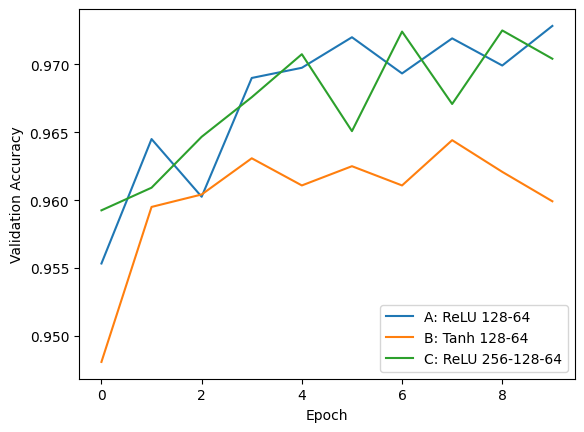

In [10]:
plt.plot(history_a.history['val_accuracy'], label='A: ReLU 128-64')
plt.plot(history_b.history['val_accuracy'], label='B: Tanh 128-64')
plt.plot(history_c.history['val_accuracy'], label='C: ReLU 256-128-64')
plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy')
plt.legend()
plt.show()

In [11]:
model_list = [model_a, model_b, model_c]
acc_list = [acc_a, acc_b, acc_c]
best_model = model_list[acc_list.index(max(acc_list))]

y_pred_prob = best_model.predict(X_test_scaled)
y_pred = np.argmax(y_pred_prob, axis=1)

print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       980
           1       0.99      0.99      0.99      1135
           2       0.94      0.98      0.96      1032
           3       0.98      0.97      0.97      1010
           4       0.97      0.97      0.97       982
           5       0.97      0.97      0.97       892
           6       0.97      0.98      0.97       958
           7       0.98      0.96      0.97      1028
           8       0.97      0.96      0.97       974
           9       0.97      0.96      0.97      1009

    accuracy                           0.97     10000
   macro avg       0.97      0.97      0.97     10000
weighted avg       0.97      0.97      0.97     10000

[[ 968    0    2    0    0    2    6    0    1    1]
 [   0 1125    4    0    0    0    2    1    2    1]
 [   1    1 1012    1    1    0    3    6    5    2]
 [   0    0    9  982    0    7    0    5

This assignment is about classifying handwritten digits from the MNIST dataset, which has 60,000 training images and 10,000 test images (28x28 pixels each). The model is an Artificial Neural Network made with TensorFlow. For preprocessing, the images are reshaped into 784 features and scaled using StandardScaler. After that, the training data is split into training and validation data (80:20). Three models were tried: Model A (ReLU, 128-64), Model B (Tanh, 128-64), and Model C (ReLU, 256-128-64). All of them were trained for 10 epochs using the Adam optimizer. On the test data, Model A got the best accuracy at 97.31%, then Model C with 96.94%, and Model B with 95.71%. So ReLU works better than Tanh here. Adding more layers and neurons in Model C didn’t make the result better, so the simpler Model A is already good enough. From the validation accuracy graph, all models go up fast in the first few epochs and then stay pretty stable, but Model C goes up and down more. From the classification report, Model A got 97% accuracy. The best f1-score is on digits 0 and 1 (0.99), and the lowest precision is on digit 2 (0.94).